In [2]:
import numpy as np
import joblib

# Load processed training and testing data
X_train_scaled = np.load("X_train_scaled.npy")
X_test_scaled = np.load("X_test_scaled.npy")
y_train = np.load("y_train.npy")
y_test = np.load("y_test.npy")

# Load label encoder
label_encoder = joblib.load("label_encoder.pkl")

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)
print("Number of classes:", len(label_encoder.classes_))

Training data: (2016638, 78)
Testing data: (504160, 78)
Training labels: (2016638,)
Testing labels: (504160,)
Number of classes: 15


In [3]:
# Check training class distribution

unique_classes, class_counts = np.unique(y_train, return_counts=True)

print("Training Class Distribution:\n")

for class_id, count in zip(unique_classes, class_counts):
    class_name = label_encoder.inverse_transform([class_id])[0]
    print(f"{class_id} = {class_name}: {count}")

Training Class Distribution:

0 = BENIGN: 1676045
1 = Bot: 1558
2 = DDoS: 102411
3 = DoS GoldenEye: 8229
4 = DoS Hulk: 138277
5 = DoS Slowhttptest: 4182
6 = DoS slowloris: 4308
7 = FTP-Patator: 4745
8 = Heartbleed: 9
9 = Infiltration: 29
10 = PortScan: 72555
11 = SSH-Patator: 2575
12 = Web Attack � Brute Force: 1176
13 = Web Attack � Sql Injection: 17
14 = Web Attack � XSS: 522


In [4]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [5]:
# Make predictions on test data
y_pred = rf_model.predict(X_test_scaled)

print("Predictions completed successfully!")

Predictions completed successfully!


In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Random Forest Evaluation Results
--------------------------------
Accuracy : 0.9986175023801968
Precision: 0.9985609708087895
Recall   : 0.9986175023801968
F1 Score : 0.9985425784649383


In [7]:
from sklearn.metrics import classification_report

print("Classification Report")
print("---------------------")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report
---------------------
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419012
           1       0.89      0.65      0.75       390
           2       1.00      1.00      1.00     25603
           3       1.00      0.99      0.99      2057
           4       1.00      1.00      1.00     34569
           5       0.99      1.00      0.99      1046
           6       1.00      0.99      0.99      1077
           7       1.00      1.00      1.00      1186
           8       1.00      0.50      0.67         2
           9       0.88      1.00      0.93         7
          10       0.99      1.00      0.99     18139
          11       1.00      1.00      1.00       644
          12       0.73      0.93      0.81       294
          13       1.00      0.25      0.40         4
          14       0.52      0.18      0.26       130

    accuracy                           1.00    504160
   macro avg       0.93      0.83   

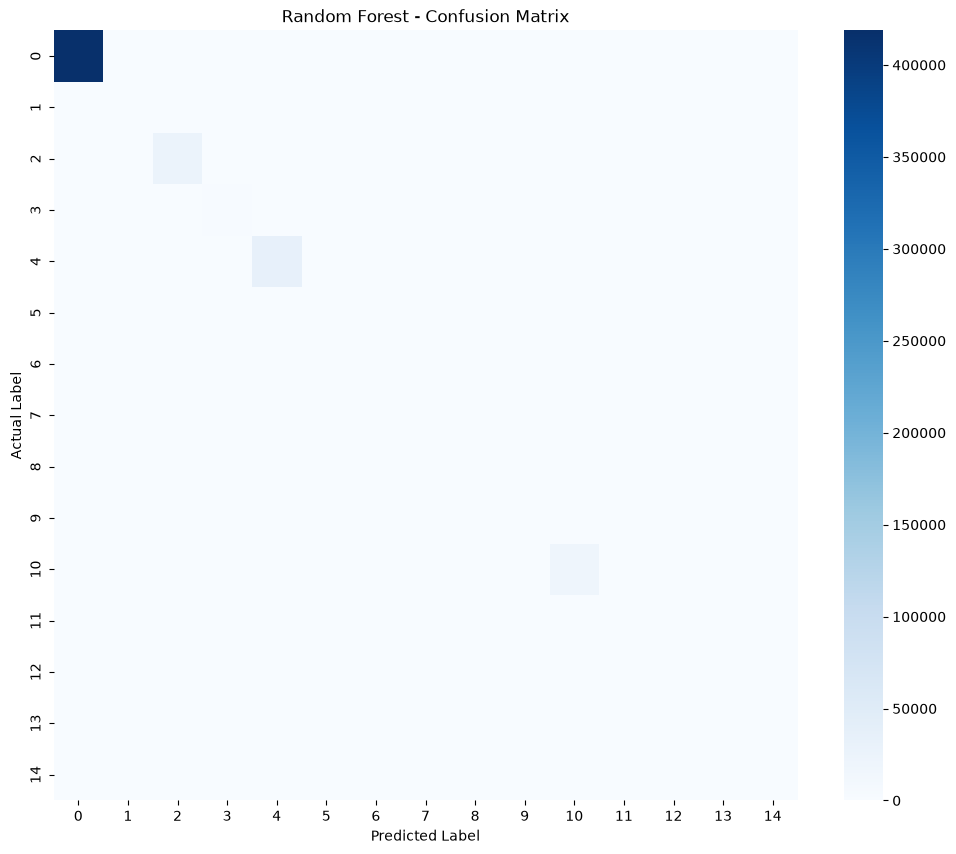

In [8]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, cmap="Blues", fmt="d")

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [10]:
import numpy as np

# Get the class names
class_names = np.unique(y_test)

print("Class names:")
print(class_names)

Class names:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


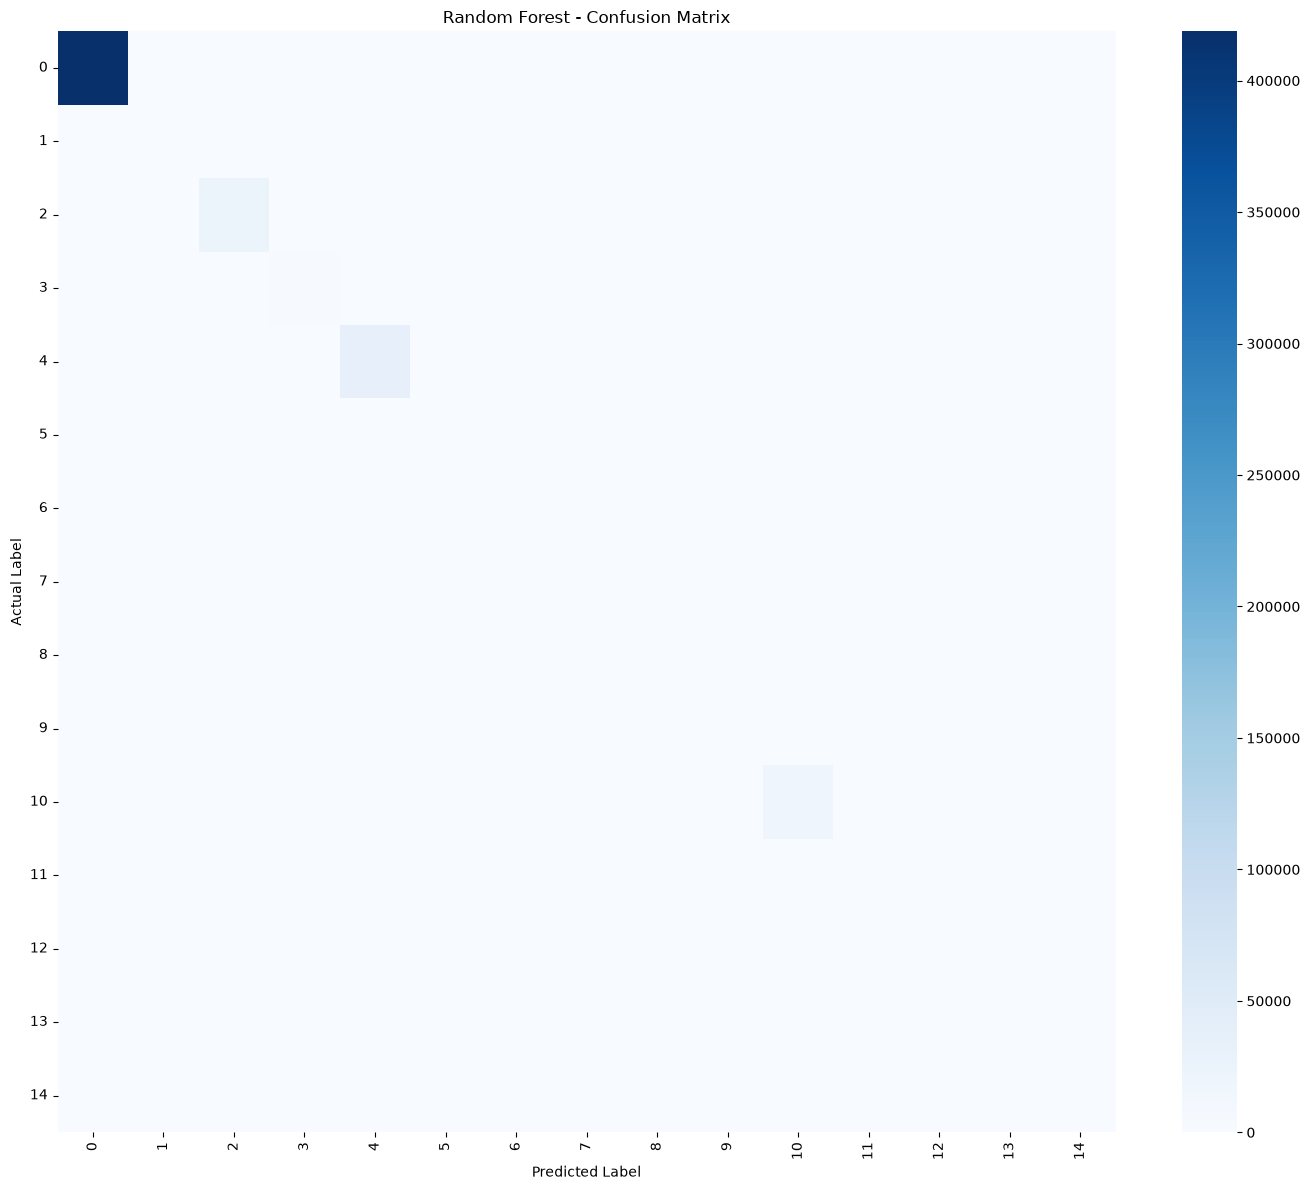

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

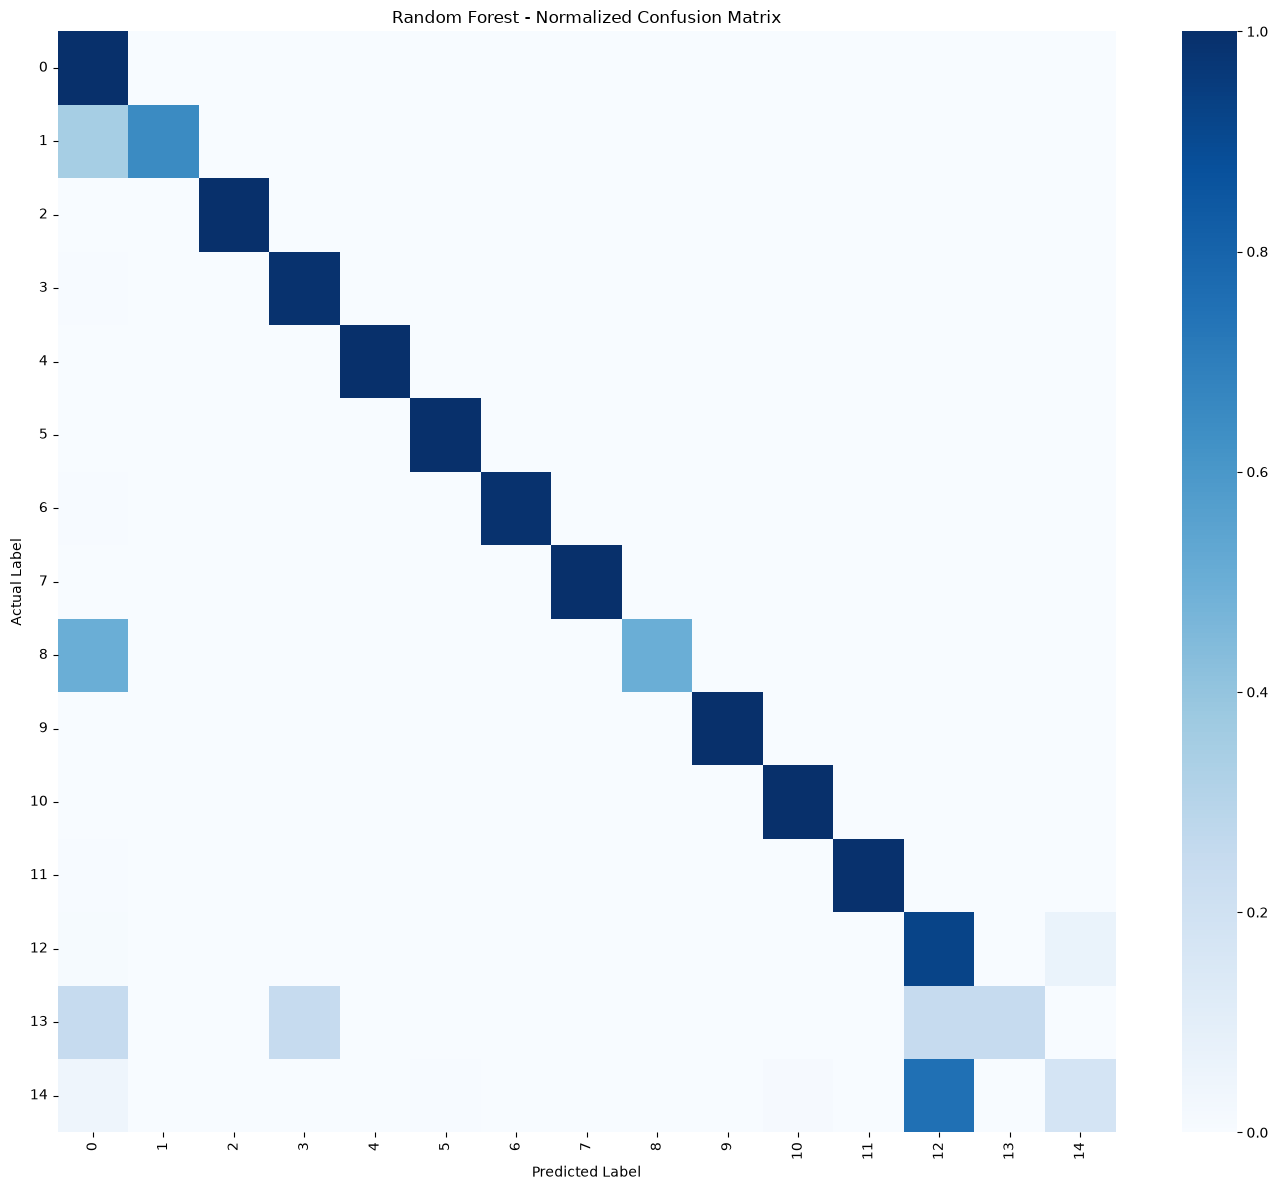

In [13]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create normalized confusion matrix
cm_normalized = confusion_matrix(
    y_test,
    y_pred,
    normalize='true'
)

# Plot
plt.figure(figsize=(14, 12))

sns.heatmap(
    cm_normalized,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("Random Forest - Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import pandas as pd

feature_names = np.load("feature_names.npy", allow_pickle=True)

print("Number of feature names:", len(feature_names))
print("Number of model features:", len(rf_model.feature_importances_))

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 20 Most Important Features:")
print(importance_df.head(20).to_string(index=False))

Number of feature names: 78
Number of model features: 78

Top 20 Most Important Features:
                     Feature  Importance
           Packet Length Std    0.067614
      Packet Length Variance    0.061696
        Avg Bwd Segment Size    0.061439
           Max Packet Length    0.049281
       Bwd Packet Length Std    0.043550
       Bwd Packet Length Max    0.042298
         Average Packet Size    0.040155
           Subflow Fwd Bytes    0.035936
 Total Length of Bwd Packets    0.033673
       Fwd Packet Length Max    0.031080
 Total Length of Fwd Packets    0.030606
           Subflow Bwd Bytes    0.027986
         Subflow Fwd Packets    0.021998
        Avg Fwd Segment Size    0.021304
      Bwd Packet Length Mean    0.020344
     Init_Win_bytes_backward    0.019851
          Packet Length Mean    0.019019
      Fwd Packet Length Mean    0.018063
                   Idle Mean    0.016643
         Fwd Header Length.1    0.015734


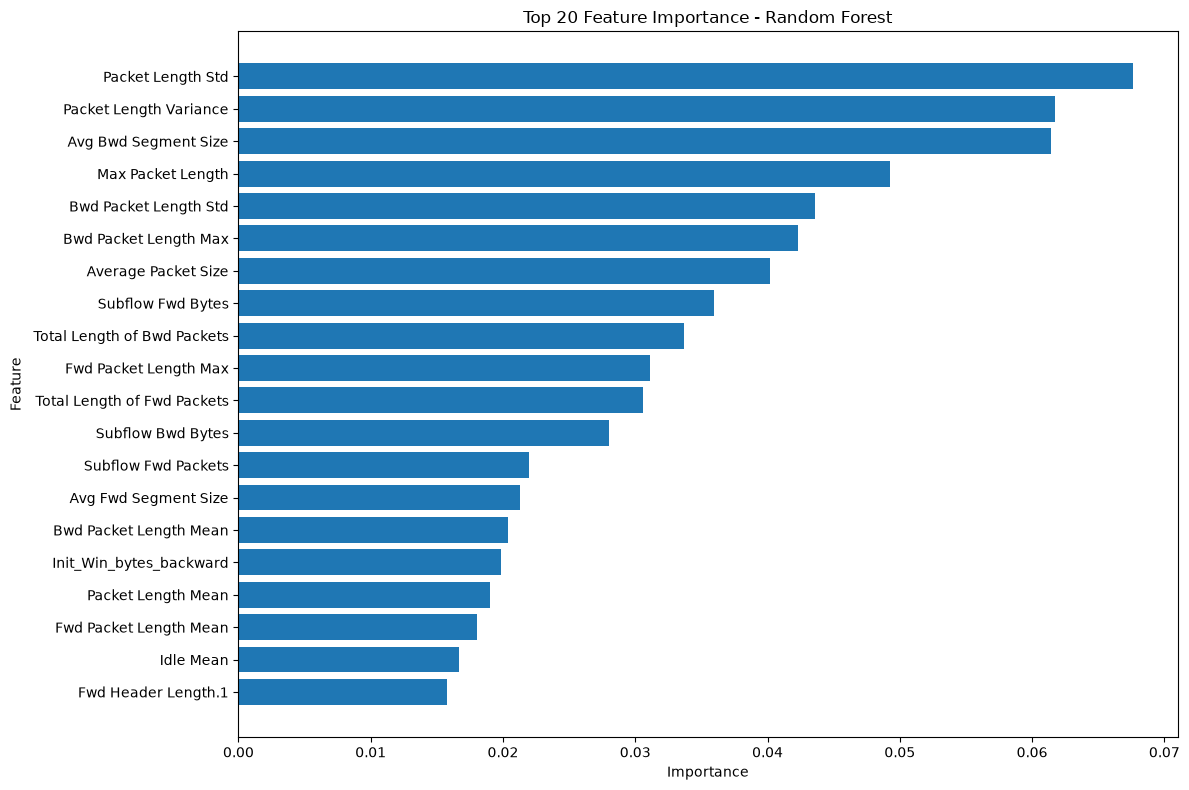

In [18]:
import matplotlib.pyplot as plt

# Select top 20 features
top_20 = importance_df.head(20)

# Plot
plt.figure(figsize=(12, 8))

plt.barh(
    top_20["Feature"][::-1],
    top_20["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

In [19]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "random_forest_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [20]:
import numpy as np

# Save feature names
np.save("feature_names.npy", feature_names)

print("Feature names saved successfully!")
print("Number of features:", len(feature_names))

Feature names saved successfully!
Number of features: 78


In [21]:
import os
import joblib
import numpy as np

# Check if saved files exist
print("Checking saved files...\n")

print("Random Forest model exists:",
      os.path.exists("random_forest_model.pkl"))

print("Feature names file exists:",
      os.path.exists("feature_names.npy"))

# Load the saved model
loaded_model = joblib.load("random_forest_model.pkl")

# Load the saved feature names
loaded_features = np.load("feature_names.npy", allow_pickle=True)

print("\nVerification:")
print("Loaded model type:", type(loaded_model).__name__)
print("Number of features:", len(loaded_features))
print("Number of model features:", len(loaded_model.feature_importances_))

Checking saved files...

Random Forest model exists: True
Feature names file exists: True

Verification:
Loaded model type: RandomForestClassifier
Number of features: 78
Number of model features: 78


In [22]:
# Test the saved model on test data

test_predictions = loaded_model.predict(X_test_scaled[:10])

print("Predictions from saved model:")
print(test_predictions)

print("\nNumber of predictions:", len(test_predictions))

Predictions from saved model:
[ 0 10  0  0  0  0  0  2  0  0]

Number of predictions: 10
